# 2. Part II

## 2.1. k-Nearest Neighbors
- In this section you will implement the k-NN algorithm and explore its performance as a function of k.

### 2.1.1. Generating the data
- A voted-center hypothesis is a function hS,v : [0, 1]2 → {0, 1, []} where S = {(x1, y1), (x2, y2), . . . , (x|S|, y|S|)} is a set of labeled centers with each xi ∈ [0, 1]2 and yi ∈ {0, 1} and v is a positive integer. 

- In this coursework we will always set v := 3 for all of of the exercises in this subsection. Where hS,v (x) = 0 if the majority of the v nearest xi’s to x in S are ‘0’, similarly for hS,v (x) = 1 and finally in certain “corner” cases the “the majority of v ...” will not be well-defined and in that case hS,v (x) = []. See Section 2.1.4 for addressing those corner cases.

- In Figure 1 one such hypothesis is visualised with |S| = 100 and v = 3. The white area is the mapping to 0 and the turquoise is the mapping to 1, the corresponding centers are green and blue.

### q6. [5 pts] Produce a visualisation of an hS,v similar to the figure.
- First we will need to generate a random h. Do this by sampling 100 centers uniformly at random from [0, 1]2 with 100 corresponding labels sampled uniformly at random from {0, 1}. Later we will need to generate more random hypotheses. Call this distribution over hypotheses generated by this random process pH.

In [14]:
%pip install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [ ]:
# an optimised kkn classifier, using vectorised k-nearest neighbours
# grid_points: test points
# X_center_points: training points
# y_center_points: binary labels of training points
# v_centers: number of nearest neighbors to consider
# returns the predicited binary labels of test points
def knn_classifier(grid_points, X_center_points, y_center_labels, v_centers):

    # computing pairwise squared Euclidean distances using matrix expansion
    # ||a - b||^2 = ||a||^2 + ||b||^2 - 2(a . b)
    distances = ((grid_points ** 2).sum(axis=1)[:, None] 
                    + (X_center_points ** 2).sum(axis=1)[None, :] 
                    - 2 * grid_points @ X_center_points.T)

    # finding indicies of the k neighbours with smallest distances
    # counting how many of them have label 1
    # assign predicted label as 1 if majority of neighbours 1, else 0
    # 2.1.4. break ties using random selection
    nearest_indices = np.argpartition(distances, v_centers - 1, axis=1)[:, :v_centers]
    ones = y_center_labels[nearest_indices].sum(axis=1)
    predicted_labels = (ones > (v_centers / 2)).astype(int)
    tie = (ones == (v_centers / 2))
    predicted_labels[tie] = np.random.randint(0, 2, tie.sum())
    return predicted_labels

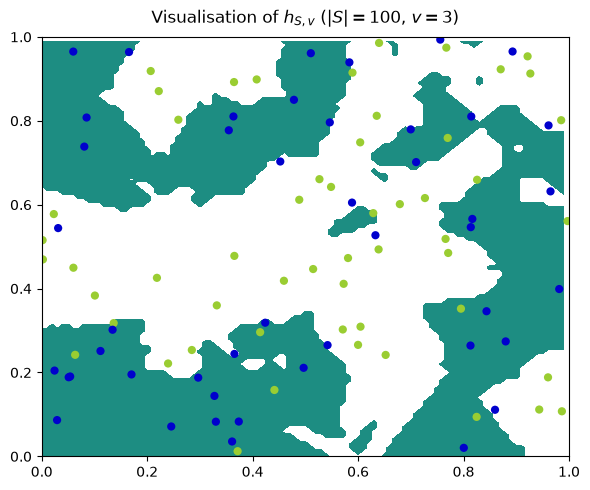

In [ ]:
# data generation
np.random.seed(5) # seeding for reproducibility
n_centers = 100 # total number of centers in S
v_centers = 3   # total number of centers that get to vote
X_center_points = np.random.rand(n_centers, 2) # random centers in [0,1]^2
y_center_labels = np.random.randint(0, 2, n_centers) # random labels in {0,1}

# decision boundary grid setup
boundary_resolution = 0.01
x_range = np.arange(0, 1, boundary_resolution)
y_range = np.arange(0, 1, boundary_resolution)
xx, yy = np.meshgrid(x_range, y_range)

# flattening meshgrid into query points, classifying and reshaping into 2D grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
predicted_grid_labels = knn_classifier(grid_points, X_center_points, y_center_labels, v_centers)
predicted_grid_labels = predicted_grid_labels.reshape(xx.shape)

# visualsation setup and generation
fig, ax = plt.subplots(figsize=(6, 5))
cmap = ListedColormap(['#FFFFFF', '#1D8D82'])
ax.contourf(xx, yy, predicted_grid_labels, cmap=cmap, alpha=1.0)

ax.scatter(
    X_center_points[y_center_labels == 0, 0], 
    X_center_points[y_center_labels == 0, 1], 
    c='yellowgreen', edgecolors='none', s=35, label='Center (0)'
)
ax.scatter(
    X_center_points[y_center_labels == 1, 0], 
    X_center_points[y_center_labels == 1, 1], 
    c='mediumblue', edgecolors='none', s=35, label='Center (1)'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(f"Visualisation of $h_{{S,v}}$ ($|S|=100$, $v={v_centers}$)", fontsize=12, pad=10)

plt.tight_layout()
plt.show()

### 2.1.2 Estimated generalization error of k-NN as a function of k
- In this section we visualise the performance as a function of k. You will produce a figure where the vertical axis is the estimated generalisation error and the horizontal axis is k = 1, . . . , 49.

- Generating our noisy data. Given an hS,v the underlying probability distribution ph(x, y) is determined by sampling an x uniformly at random from [0, 1]2 and then its corresponding y value is then generated by flipping biased coin P (heads) = 0.8/P (tails) = 0.2 if heads comes up then y = hS,3(x) otherwise y is sampled uniformly at random from {0, 1}. When you generate training and test sets they will both come from this distribution.

### q7. [7 pts] 
- a) Produce a visualisation using Protocol A (see Figure 2). 
- b) Using roughly 5 sentences explain why the figure is the approximate shape that it is and comment on any interesting features of the figure.


In [ ]:
# sample a random knn hypothesis h_S,v from the p_H
# generates n_centers uniform points in [0,1]^2 
# with random binary labels in {0,1}
def sample_h(n_centers):
    X_center_points = np.random.rand(n_centers, 2) 
    y_center_labels = np.random.randint(0, 2, n_centers) 
    return X_center_points, y_center_labels

# sample m labelled points from the noisy joint distibution p_h(x,y)
# draws x ~ uniform [0,1]^2
# sets y = h_S,v(x) with prob 0.8, and uniform {0,1} noise with prob 0.2
def sample_data(m, X_center_points, y_center_labels, v_centers):
    X_data = np.random.rand(m, 2)
    y_data = knn_classifier(X_data, X_center_points, y_center_labels, v_centers)
    tails = np.random.rand(m) < 0.2
    y_data[tails] = np.random.randint(0, 2, tails.sum())
    return X_data, y_data

In [ ]:
# main Protocol A loop
# following the algorithm outlined in the brief
def knn_protocol_a(n_centers, v_centers, n_train, n_test, rs, ks):
    generalisation_errors = np.zeros((len(rs), len(ks)))

    for r_idx, r in enumerate(rs):
        X_center_points, y_center_labels = sample_h(n_centers)
        X_train, y_train = sample_data(n_train, X_center_points, y_center_labels, v_centers)
        X_test, y_test = sample_data(n_test, X_center_points, y_center_labels, v_centers)

        for k_idx, k in enumerate(ks):
            predicted_labels = knn_classifier(X_test, X_train, y_train, k)
            generalisation_errors[r_idx, k_idx] = np.mean(predicted_labels != y_test)

    return generalisation_errors

# data generation
np.random.seed(5)
n_centers, v_centers = 100, 3
n_train, n_test = 4000, 1000
rs = np.arange(100)
ks = np.arange(1, 50)
generalisation_errors = knn_protocol_a(n_centers, v_centers, n_train, n_test, rs, ks)
mean_errors = generalisation_errors.mean(axis=0)

# reporting the best k and its corresponding error
print(f'best k = {ks[mean_errors.argmin()]}, error = {mean_errors.min():.4f}')
print("k = 1..10: ", np.round(mean_errors[:10], 4))
print(f'k = 49 error = {mean_errors[-1]:.4f}')

best k = 7, error = 0.1441
k = 1..10:  [0.2045 0.2093 0.1584 0.1613 0.1467 0.1493 0.1441 0.1462 0.1445 0.1459]
k = 49 error = 0.1687


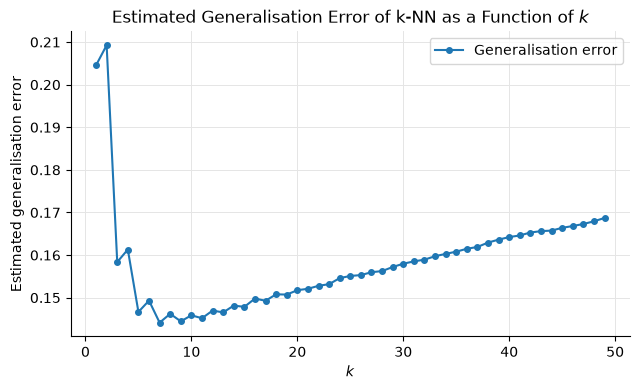

In [ ]:
# visualsation setup and generation
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(ks, mean_errors, 'o-', ms=4, linewidth=1.5, label="Generalisation error")

ax.set_title('Estimated Generalisation Error of k-NN as a Function of $k$')
ax.set_xlabel('$k$')
ax.set_ylabel('Estimated generalisation error')

ax.grid(True, color='#E5E5E5', linestyle='-', linewidth=0.7)
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend()
plt.tight_layout()
plt.savefig('knn-q7-protocol-a.png', bbox_inches='tight')
plt.show()

q7) b) explaining the graph
- The graph is an asymmetrical U-shaped curve that reflects the bias-variance tradeoff. The error is the highest at k=1 (~0.205), it then falls sharply to a minimum error at the optimal range of k=7..11 (~0.145), and then it rises near-linearly at a slow rate to k-49 (~0.17). And the curve never reaches the bayes error of 0.1 (ie. the label noise).
- At very small k the model has a high variance and overfits. Essentially memorising the nearest neighbours only, so it also absorbs the label noise (each label is wrong with the probability 0.2 x 1/2 = 0.1), rather than learning the underlying hypothesis h_S,v.
- As k increases towards the optimal range, the majority vote over each neighbourhood acts as a filter, it cancels out the noisy labels while still preserving the class boundaries of h_S,v.
- Beyond this the model becomes increasingly biased and begins to underfit. The neighbourhood grows large enough to include points from the opposite side of the boundary, so small regions of h_S,v are out-voted and blurred. The rise is gentle as only the test points near the boundaries are affected.
- The "zigzag/ sawtooth" pattern at small k arises because an even k either agrees with the k-1 vote or ties and must be broken uniformly at (pseudo) random. That gives it the same expected error as k-1, while its extra/ more distant neighbour adds slight bias, so each even k is marginally worse than the odd k before it. This effect fades as k grows large.

### 2.1.3 Determine the optimal k as a function of the number of training points (m)
- In this section you will estimate the optimal k as a function of the number of training points. Perform the following experimental protocol.

### 2.1.4 Additional Clarifications
- Note both the k-NN algorithm and the hypothesis h can produced “undefined” results in certain corner cases for individual x’s. Resolve these case by generating either the label or prediction uniformly at random.

### q8. [8 pts] 
- a) Produce a visualisation using Protocol B (see Figure 3). I.e, plotting m versus optimal k.
- b) Using roughly 4 sentences explain why the figure is the approximate shape that it is.

In [ ]:
# main Protocol B loop
# following the algorithm outlined in the brief
def knn_protocol_b(n_centers, v_centers, n_test, ms, rs, ks):
    optimal_ks = np.zeros((len(ms), len(rs)))

    for m_idx, m in enumerate(ms):
        for r_idx, r in enumerate(rs):
            X_center_points, y_center_labels = sample_h(n_centers)
            X_train, y_train = sample_data(m, X_center_points, y_center_labels, v_centers)
            X_test, y_test = sample_data(n_test, X_center_points, y_center_labels, v_centers)

            generalisation_errors = np.zeros(len(ks))
            for k_idx, k in enumerate(ks):
                predicted_labels = knn_classifier(X_test, X_train, y_train, k)
                generalisation_errors[k_idx] = np.mean(predicted_labels != y_test)

            best_ks = ks[generalisation_errors == generalisation_errors.min()]
            optimal_ks[m_idx, r_idx] = np.random.choice(best_ks)

    return optimal_ks

# data generation
np.random.seed(5)
n_centers, v_centers = 100, 3
n_test = 1000
ms = np.array([100] + list(range(500, 4001, 500)))
rs = np.arange(100)
ks = np.arange(1, 50)
optimal_ks = knn_protocol_b(n_centers, v_centers, n_test, ms, rs, ks)
mean_optimal_ks = optimal_ks.mean(axis=1)

# reporting the mean optimal k for each m
for m, k in zip(ms, mean_optimal_ks):
    print(f'm = {m}: mean optimal k = {k:.2f}')

m = 100: mean optimal k = 3.72
m = 500: mean optimal k = 6.19
m = 1000: mean optimal k = 7.42
m = 1500: mean optimal k = 8.44
m = 2000: mean optimal k = 8.19
m = 2500: mean optimal k = 9.89
m = 3000: mean optimal k = 9.68
m = 3500: mean optimal k = 9.98
m = 4000: mean optimal k = 10.09


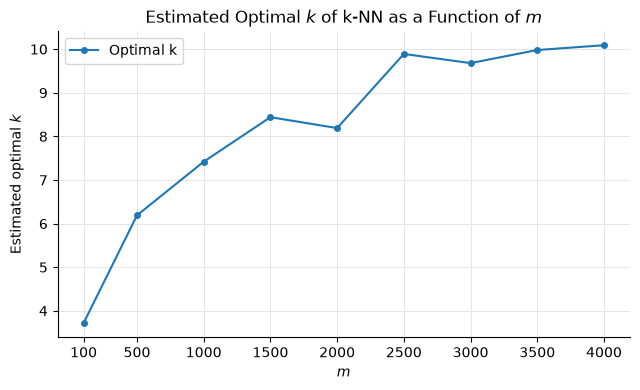

In [ ]:
# visualsation setup and generation
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(ms, mean_optimal_ks, 'o-', ms=4, linewidth=1.5, label="Optimal k")

ax.set_title('Estimated Optimal $k$ of k-NN as a Function of $m$')
ax.set_xlabel('$m$')
ax.set_ylabel('Estimated optimal $k$')
ax.set_xticks(ms)

ax.grid(True, color='#E5E5E5', linestyle='-', linewidth=0.7)
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend()
plt.tight_layout()
plt.savefig('knn-q8-protocol-b.png', bbox_inches='tight')
plt.show()

q8) b) explaining the graph
- The graph shows a sub-linear generally increasing trend. The estimated optimal k rises from ~3.7 at m=100 to ~10.1 at m=4000, which is consistent with the minimum of the Protocol A curve observed in q7. The small dips (e.g. at m=2000) are run-to-run noise, the error curve is very flat near its minimum, so the per-run optimial k can vary considerably.
- As m increases, the training data density increases within the [0,1]^2 domain, so the k-th nearest neighbour is closer to each test point (i.e. the neighbourhood radius scales roughly as √(k/m)).
- The higher density lets the algorithm safely increase k. A larger majority vote filters out more of the random label noise and reduces variance, without the neighbourhood growing large enough to cross the decision boundaries of h_S,v and introduce significant bias.
- The optimal k grows sub-linearly, and each extra neighbour reduces the noise by less, while the risk of crossing the boundary keeps growing. If k grew linearly with m (i.e. so that k/m does not tend to 0), the neighbourhood would never shrink, and the model would not be able to resolve the fine local strucutre of the true h_S,v.